**[1]**

# Proyecto completo de Machine Learning: precio del gasóleo en las gasolineras de España

## Enlace vídeo YouTube: https://youtu.be/J1HzpghMQ2o

## 1. Obtención de datos

**Fuente:** Ministerio para la Transición Ecológica y el Reto Demográfico (MITECO),
servicio REST de precios de carburantes en estaciones de servicio terrestres.

**Cómo se obtienen los datos originalmente:** por ley, todas las estaciones de servicio de España
están obligadas a comunicar al Ministerio los precios de venta al público de sus carburantes.
Los envían ellas mismas o a través de su operador mayorista (la petrolera que les suministra).
El Ministerio publica esos precios en tiempo real.

**Cómo los he obtenido yo:** el servidor del Ministerio rechaza las conexiones desde Google Colab,
así que descargué los datos con un script de Python en mi ordenador y los guardé en un CSV.

**Fecha de los datos:** 9 de noviembre de 2026, 9:42 h. Son una "foto" de los precios en ese momento.

In [1]:
# [2]
# Librerías que vamos a usar en todo el proyecto
import numpy as np                  # cálculos numéricos
import pandas as pd                 # tablas de datos (DataFrames)
import matplotlib.pyplot as plt     # gráficas
import seaborn as sns               # gráficas más elaboradas (mapas de calor, etc.)

# Dirección "raw" (en bruto) del CSV en GitHub.
# raw.githubusercontent.com devuelve el archivo tal cual, sin la página web de GitHub alrededor
# (si usáramos la dirección normal de github.com, nos daría HTML, como pasó con el archivo del navegador).

url_datos = "https://raw.githubusercontent.com/HerranzP-Lorena/Proyecto_ML_Lorena_Herranz/main/gasolineras_2026-11-09.csv"

# read_csv acepta tanto rutas de archivo como direcciones web
gasolineras = pd.read_csv(url_datos)

gasolineras.shape

(11479, 41)

In [2]:
# [3]
# Las columnas Margen, Remisión y Tipo Venta vienen en códigos (letras).
# Para saber qué valores tienen y cuántas gasolineras hay con cada uno,
# las recorremos con un for y aplicamos value_counts() a cada una.
for columna in ["Margen", "Remisión", "Tipo Venta"]:
    # value_counts() cuenta cuántas veces aparece cada valor distinto en la columna.
    print(gasolineras[columna].value_counts(), "\n")

Margen
D    6094
I    2724
N    2661
Name: count, dtype: int64 

Remisión
dm    7446
OM    4033
Name: count, dtype: int64 

Tipo Venta
P    11479
Name: count, dtype: int64 



**[4]**

Antes de describir las columnas, compruebo qué valores tienen las tres que vienen en códigos:

* **Margen:** D (6.094 gasolineras), I (2.724) y N (2.661).
* **Remisión:** dm (7.446) y OM (4.033). Esto indica quién envía los precios de la gasolinera al Ministerio. dm los envía la propia gasolinera, OM el mayorista, es decir, la petrolera que suministra a la gasolinera.
* **Tipo Venta:** todas las gasolineras tienen el valor P (venta al público), así que esta columna no aporta información.

**[5]**

## 2. Descripción de los datos

El dataset tiene **11.479 filas** (una por gasolinera) y **41 columnas**. Estas son las que voy a usar:

| Columna | Significado |
|---|---|
| `Precio Gasoleo A` | Precio del gasóleo normal en €/litro. **Es el valor a predecir (target).** |
| `Latitud`, `Longitud (WGS84)` | Coordenadas de la gasolinera. |
| `Provincia` | Provincia en la que está. |
| `Municipio`, `Localidad` | Municipio y localidad. |
| `Rótulo` | Marca o nombre del cartel (REPSOL, CEPSA, PLENOIL...). Si la gasolinera no tiene marca, aparece su número de registro (por ejemplo, "Nº 10.935"). |
| `Horario` | Horario de apertura, en texto (por ejemplo, "L-D: 24H"). |
| `Margen` | Lado de la carretera: D = derecho, I = izquierdo, N = no aplicable. |
| `Remisión` | Quién comunica los precios al Ministerio. Interpretación: dm = la propia gasolinera, OM = su operador mayorista. |

**Columnas que no voy a usar:**

** **Los demás precios** (gasolina 95, gasolina 98, gasóleo premium, AdBlue, hidrógeno, etc.). No los uso por dos motivos:
  * **Harían trampa.** Los precios de una misma gasolinera se mueven juntos: si es cara, lo es en todos sus carburantes,
    porque dependen de lo mismo (la marca, la zona, los impuestos). El modelo aprendería a copiar el precio de la gasolina
    para adivinar el del gasóleo, sin aprender qué hace que una gasolinera sea cara o barata, que es el objetivo del proyecto.
  * **No tendrían sentido en la práctica.** Todos los precios se publican a la vez: si ya conoces el precio de la gasolina
    de una gasolinera, también conoces el del gasóleo y no necesitas predecirlo. El modelo es útil precisamente cuando
    no se conocen los precios, por ejemplo para estimar a qué precio debería vender una gasolinera nueva.
  * Además, muchas gasolineras no venden la mayoría de esos carburantes, así que esas columnas tienen muchos valores nulos.
* **`Tipo Venta`**: todas las filas tienen el valor P (venta al público), así que no aporta información.
* **`IDEESS`, `IDMunicipio`, `IDProvincia`, `IDCCAA`, `C.P.`, `Dirección`**: son identificadores y direcciones. No sirven para predecir, o repiten información que ya está en otras columnas.
* **`% BioEtanol`, `% Éster metílico`**: porcentajes de biocombustible en las mezclas. En el caso del éster metílico, solo 29 gasolineras tienen un valor distinto de 0, así que no aporta información.

**[6]**

## 3. Exploración y visualización de los datos

In [3]:
# [7]
# info() muestra, para cada columna:
#   - cuántos valores NO nulos tiene (si hay menos de 11479, el resto son nulos)
#   - de qué tipo es
gasolineras.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11479 entries, 0 to 11478
Data columns (total 41 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   C.P.                                11479 non-null  int64  
 1   Dirección                           11479 non-null  object 
 2   Horario                             11479 non-null  object 
 3   Latitud                             11479 non-null  object 
 4   Localidad                           11479 non-null  object 
 5   Longitud (WGS84)                    11479 non-null  object 
 6   Margen                              11479 non-null  object 
 7   Municipio                           11479 non-null  object 
 8   Precio Adblue                       2946 non-null   object 
 9   Precio Amoniaco                     0 non-null      float64
 10  Precio Biodiesel                    29 non-null     object 
 11  Precio Bioetanol                    1 non

**[8]**

Los precios y las coordenadas aparecen como texto (`object`) en vez de como números,
porque vienen con coma decimal ("1,459") y Python usa el punto. Hay que convertirlos.

Además, renombro las dos columnas que más voy a usar para que sean más cómodas de escribir.

In [4]:
# [9]
# --- 1. Lista de columnas que deberían ser números pero vienen como texto ---

# List comprehension: recorre todas las columnas y se queda con las que empiezan por "Precio"
columnas_numericas = [c for c in gasolineras.columns if c.startswith("Precio")]

# Añadimos a la lista las coordenadas y los dos porcentajes, que también vienen con coma
columnas_numericas += ["Latitud", "Longitud (WGS84)", "% BioEtanol", "% Éster metílico"]


# --- 2. Convertimos cada columna de texto a número ---

for columna in columnas_numericas:
    gasolineras[columna] = pd.to_numeric(
        gasolineras[columna]
            .astype(str)                              # tratamos la columna como texto
            .str.replace(",", ".", regex=False),      # cambiamos la coma decimal por punto
        errors="coerce"                               # si algún valor no se puede convertir, lo deja como nulo (NaN) en vez de dar error
    )


# --- 3. Renombramos las dos columnas que más vamos a usar, para escribirlas más fácil ---

gasolineras = gasolineras.rename(columns={
    "Precio Gasoleo A": "precio_gasoleo_a",
    "Longitud (WGS84)": "Longitud"
})


# --- 4. Comprobación: estas tres columnas ya deberían salir como float64 ---

gasolineras[["precio_gasoleo_a", "Latitud", "Longitud"]].info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11479 entries, 0 to 11478
Data columns (total 3 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   precio_gasoleo_a  11261 non-null  float64
 1   Latitud           11479 non-null  float64
 2   Longitud          11479 non-null  float64
dtypes: float64(3)
memory usage: 269.2 KB


In [5]:
# [10]
# isnull() marca con True los valores nulos; sum() cuenta cuántos True hay
# -> número de gasolineras que NO venden gasóleo A
print("Gasolineras sin precio de gasóleo A:", gasolineras["precio_gasoleo_a"].isnull().sum())

# != 0 marca con True las filas cuyo valor no es 0; sum() las cuenta
# -> comprobamos si la columna "% Éster metílico" tiene información o es todo ceros
print("Gasolineras con % Éster metílico distinto de 0:", (gasolineras["% Éster metílico"] != 0).sum())

# describe() da las estadísticas básicas del precio:
#   count = nº de valores, mean = media, std = desviación típica (cuánto se separan de la media),
#   min / max = mínimo y máximo, 25% / 50% / 75% = cuartiles (el 50% es la mediana)
gasolineras["precio_gasoleo_a"].describe()

Gasolineras sin precio de gasóleo A: 218
Gasolineras con % Éster metílico distinto de 0: 29


,precio_gasoleo_a
count,11261.000000
mean,1.869379
std,0.100835
min,1.381000
25%,1.787000
50%,1.899000
75%,1.950000
max,2.249000


**[11]**

**Observaciones:**

* 218 gasolineras no tienen precio de gasóleo A (no lo venden). Habrá que eliminarlas, porque no se puede entrenar con filas que no tienen el valor a predecir.
* La columna `% Éster metílico` solo tiene un valor distinto de 0 en 29 gasolineras, así que no aporta información.
* El precio medio del gasóleo A es de 1,869 €/litro y la mediana de 1,899 €/litro.
* El 50 % central de las gasolineras está entre 1,787 y 1,950 €/litro: los precios están bastante concentrados (desviación típica de 0,10 €).
* El mínimo, 1,381 €/litro, está muy alejado del resto. La media es menor que la mediana porque hay un grupo pequeño de gasolineras mucho más baratas. Mi hipótesis es que son las de Canarias, Ceuta y Melilla, que tienen menos impuestos sobre los carburantes. Lo compruebo más adelante.

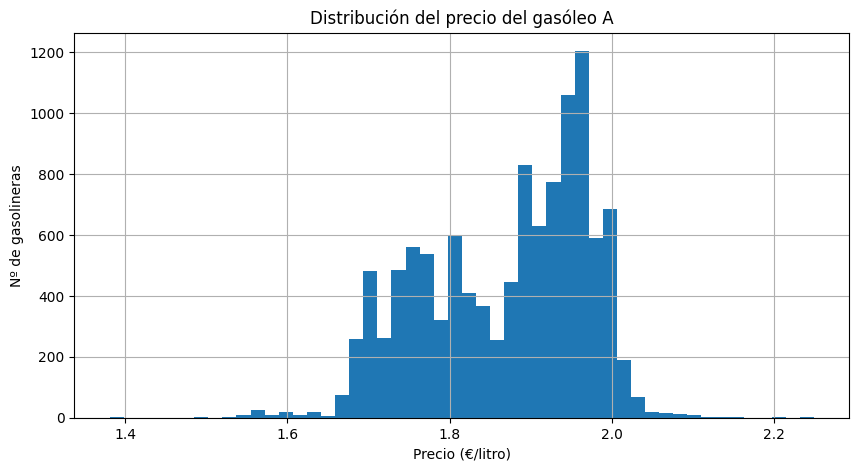

In [6]:
# [12]
# Histograma: divide el rango de precios en 50 franjas (bins)
# y dibuja una barra con cuántas gasolineras hay en cada franja
gasolineras["precio_gasoleo_a"].hist(bins=50, figsize=(10, 5))   # figsize = tamaño del gráfico (ancho, alto)

plt.title("Distribución del precio del gasóleo A")   # título del gráfico
plt.xlabel("Precio (€/litro)")                       # texto del eje horizontal
plt.ylabel("Nº de gasolineras")                      # texto del eje vertical
plt.show()                                           # muestra el gráfico

**[13]**

**Observaciones del histograma:**

* La distribución tiene **dos picos**: un grupo de gasolineras entre 1,70 y 1,80 €/litro y otro grupo más numeroso entre 1,90 y 2,00 €/litro. Esto sugiere que hay dos tipos de gasolineras con políticas de precio diferentes. Mi hipótesis es que el grupo barato corresponde a gasolineras de bajo coste o independientes y el caro a las grandes marcas. Lo compruebo más adelante con la columna `Rótulo`.
* Hay una cola de pocas gasolineras muy baratas, entre 1,40 y 1,65 €/litro, separada del resto. Encaja con la hipótesis de Canarias, Ceuta y Melilla.
* También hay unas pocas gasolineras caras por encima de 2,05 €/litro, hasta un máximo de 2,25.

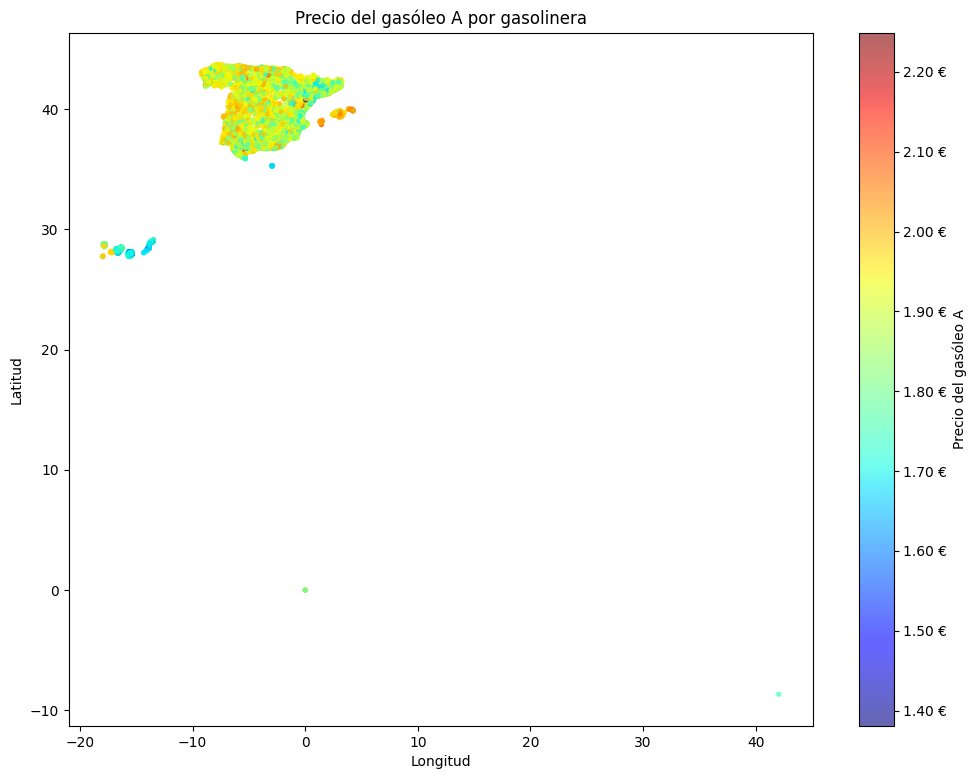

In [7]:
# [14]
import matplotlib.ticker as ticker   # para dar formato a los números de la barra de colores

# Nos quedamos solo con las gasolineras que tienen precio de gasóleo A
# (las 218 sin precio no se pueden colorear)
con_precio = gasolineras.dropna(subset=["precio_gasoleo_a"])

plt.figure(figsize=(12, 9))   # tamaño del gráfico (ancho, alto)

# Gráfico de dispersión: cada punto es una gasolinera
#   x = longitud (este-oeste), y = latitud (norte-sur) -> los puntos forman el mapa de España
#   c = color según el precio; cmap="jet" = escala de azul (barato) a rojo (caro)
#   s = tamaño de los puntos; alpha = transparencia (0 invisible, 1 opaco)
grafico = plt.scatter(
    x=con_precio["Longitud"],
    y=con_precio["Latitud"],
    c=con_precio["precio_gasoleo_a"],
    cmap="jet",
    s=8,
    alpha=0.6
)

plt.title("Precio del gasóleo A por gasolinera")
plt.xlabel("Longitud")
plt.ylabel("Latitud")

# Barra lateral
barra = plt.colorbar(grafico)
barra.set_label("Precio del gasóleo A")
barra.ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda valor, _: f"{valor:.2f} €"))   # muestra los valores como "1.90 €"

plt.show()

**[15]**

**Observaciones del mapa:**

* **Canarias** aparece en azul claro (en torno a 1,65 €/litro): es la zona más barata de España.
  Esto confirma la hipótesis de que el grupo de gasolineras muy baratas del histograma corresponde
  a territorios con menos impuestos sobre los carburantes.
* **Ceuta y Melilla** (los dos puntos al sur de Andalucía) también tienen precios bajos, por el mismo motivo.
* **Baleares** aparece en naranja: está entre las zonas más caras.
* Con este tamaño de mapa no se distinguen bien las diferencias entre zonas; las analizo después con el mapa corregido y el precio medio por provincia.

**Errores detectados en los datos:**

* Hay un punto en las coordenadas **(0, 0)**, en mitad del océano. Son coordenadas a cero,
  es decir, gasolineras sin su ubicación real registrada (al analizarlo, resultan ser 4).
* Hay otra en latitud -9 y longitud 42, en el océano Índico. Lo más probable es que tenga
  **la latitud y la longitud intercambiadas**: latitud 42 y longitud -9 corresponden a Galicia.
* Estos dos puntos hacen que el mapa se vea encogido, porque los ejes se estiran para incluirlos.
  Los analizo a continuación para decidir si se pueden corregir o hay que eliminarlos.

In [8]:
# [16]
# Buscamos las gasolineras con coordenadas imposibles para España.
# España (incluida Canarias) está más o menos entre latitud 27 y 44, y longitud -19 y 5.

coordenadas_raras = gasolineras[
    (gasolineras["Latitud"] < 27) | (gasolineras["Latitud"] > 44) |
    (gasolineras["Longitud"] < -19) | (gasolineras["Longitud"] > 5)
]

# Mostramos solo las columnas que nos ayudan a identificar dónde está de verdad cada una
coordenadas_raras[["Rótulo", "Dirección", "Municipio", "Provincia", "Latitud", "Longitud", "precio_gasoleo_a"]]

,Rótulo,Dirección,Municipio,Provincia,Latitud,Longitud,precio_gasoleo_a
1815,PETROZAL,"PASSATGE Moçambic, 2",Barcelona,BARCELONA,0.000000,0.000000,1.799
3336,REPSOL,"BARRIO EL OTERO, 7",Piélagos,CANTABRIA,0.000000,0.000000,2.018
7086,SUPER GASOIL,"AVENIDA ANDALUCIA DE, 519",Valdemoro,MADRID,0.000000,0.000000,1.819
7542,ADRIDAN,AUTOVIA RM12 KM. 0,Cartagena,MURCIA,0.000000,0.000000,1.799
8746,GUAY,CARRETERA ANTA KM. 1,Tui,PONTEVEDRA,-8.659472,42.037472,1.749


**[17]**

**Análisis de las coordenadas erróneas:**

* **4 gasolineras tienen coordenadas (0, 0)**, de Barcelona, Cantabria, Madrid y Murcia.
  No tienen su ubicación real registrada y no hay forma de recuperarla a partir del dataset.
  Como son solo 4 de 11.479 (un 0,03 %), las elimino.
* **La gasolinera de Tui (Pontevedra) tiene la latitud y la longitud intercambiadas.**
  Al darles la vuelta, latitud 42,04 y longitud -8,66, la ubicación coincide con Tui.
  Esta no se elimina: se corrige.

In [9]:
# [18]
# --- 1. Corregimos la gasolinera con latitud y longitud intercambiadas (Tui) ---

# Localizamos la fila: en España la latitud nunca es negativa, así que basta con buscar Latitud < 0
intercambiadas = gasolineras["Latitud"] < 0

# Intercambiamos los valores de las dos columnas SOLO en esa fila.
# .loc[filas, columnas] selecciona una parte de la tabla.
# .values coge los valores "en bruto", para que pandas no intente emparejarlos por nombre de columna.
gasolineras.loc[intercambiadas, ["Latitud", "Longitud"]] = gasolineras.loc[intercambiadas, ["Longitud", "Latitud"]].values


# --- 2. Eliminamos las gasolineras con coordenadas (0, 0) ---

# Contamos cuántas filas hay antes de eliminar, para comprobar que se borran exactamente 4
filas_antes = len(gasolineras)

# Nos quedamos con las filas en las que NO se cumple que latitud y longitud sean ambas 0.
# El símbolo ~ significa "no" (invierte la condición)
gasolineras = gasolineras[~((gasolineras["Latitud"] == 0) & (gasolineras["Longitud"] == 0))]

print("Filas eliminadas:", filas_antes - len(gasolineras))   # debería salir 4
print("Filas que quedan:", len(gasolineras))                 # debería salir 11475


# --- 3. Comprobación: la gasolinera de Tui

gasolineras[gasolineras["Municipio"] == "Tui"][["Rótulo", "Municipio", "Latitud", "Longitud"]]

Filas eliminadas: 4
Filas que quedan: 11475


,Rótulo,Municipio,Latitud,Longitud
8746,GUAY,Tui,42.037472,-8.659472
8747,REPSOL,Tui,42.048722,-8.643556
8748,REPSOL,Tui,42.041444,-8.647750
8749,SBC,Tui,42.036694,-8.664028
8750,OUTLETUI,Tui,42.041278,-8.662000
8751,GASLANDER,Tui,42.037000,-8.665194
8752,SERTUY,Tui,42.069528,-8.631472
8753,SERTUY,Tui,42.069626,-8.631987


**[19]**

Tras la corrección, la gasolinera de Tui (rótulo GUAY) tiene latitud 42,04 y longitud -8,66,
prácticamente las mismas coordenadas que las otras 7 gasolineras del municipio.
Esto confirma que el error era que latitud y longitud estaban intercambiadas.

Se han eliminado las 4 gasolineras con coordenadas (0, 0). Quedan **11.475 gasolineras**.

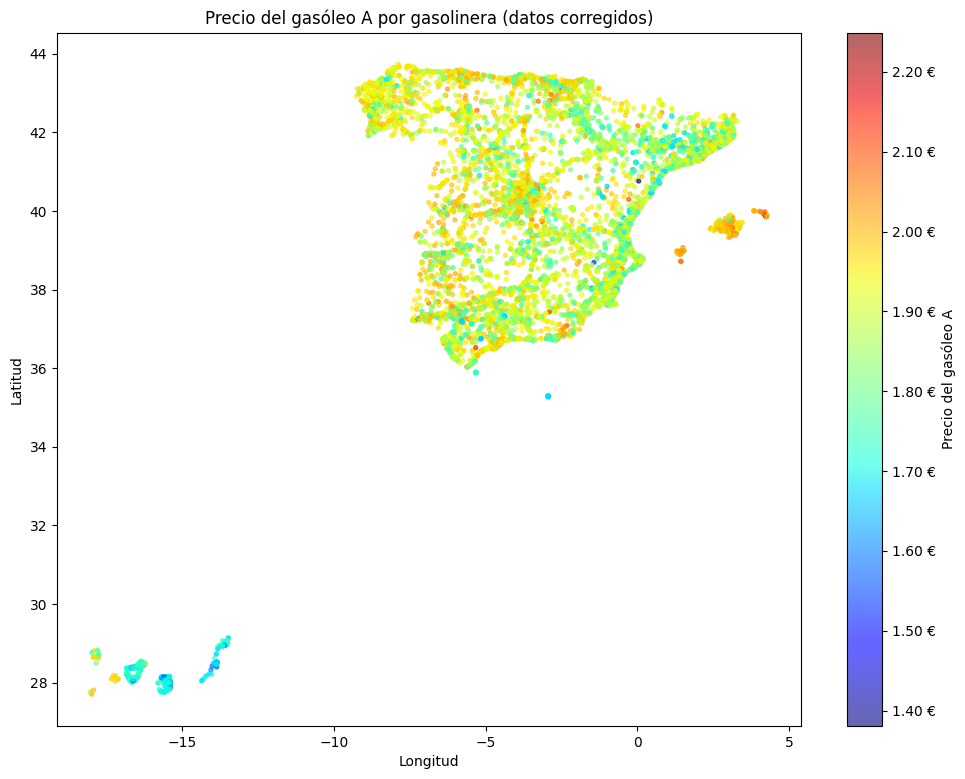

In [10]:
# [20]
# Mismo mapa que antes, pero ahora con los datos corregidos.
# Al no haber puntos en (0, 0) ni en el océano Índico, los ejes ya no se estiran y España se ve más grande.

# Nos quedamos solo con las gasolineras que tienen precio de gasóleo A
con_precio = gasolineras.dropna(subset=["precio_gasoleo_a"])

plt.figure(figsize=(12, 9))   # tamaño del gráfico (ancho, alto)

# Cada punto es una gasolinera: x = longitud, y = latitud, color = precio
grafico = plt.scatter(
    x=con_precio["Longitud"],
    y=con_precio["Latitud"],
    c=con_precio["precio_gasoleo_a"],
    cmap="jet",      # escala de color: azul = barato, rojo = caro
    s=8,             # tamaño de los puntos
    alpha=0.6        # transparencia, para que se vean las zonas con muchos puntos superpuestos
)

plt.title("Precio del gasóleo A por gasolinera (datos corregidos)")
plt.xlabel("Longitud")
plt.ylabel("Latitud")

# Barra de colores con los precios en formato "1.90 €"
barra = plt.colorbar(grafico)
barra.set_label("Precio del gasóleo A")
barra.ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda valor, _: f"{valor:.2f} €"))

plt.show()

**[21]**

**Observaciones del mapa corregido:**

* Al eliminar los errores de coordenadas, el mapa ya muestra solo España y se aprecian las diferencias entre zonas.
* **Canarias** sigue siendo la zona más barata (tonos azules y cian). Las islas más occidentales
  (El Hierro y La Palma, a la izquierda del todo) aparecen algo más caras que el resto del archipiélago.
* **Baleares** aparece en naranja: es de las zonas más caras de España.
* En la **península**, el noreste (Cataluña) y parte de la costa mediterránea tienen más gasolineras
  en verde y cian (más baratas). El norte y el interior tienen más tonos amarillos y naranjas (más caras).
* Los puntos se agrupan formando líneas que siguen las **carreteras principales**, porque es donde se concentran las gasolineras.
* El mapa da una idea general, pero hay demasiados puntos superpuestos para comparar zonas con precisión.
  Para eso, a continuación calculo el **precio medio por provincia**.

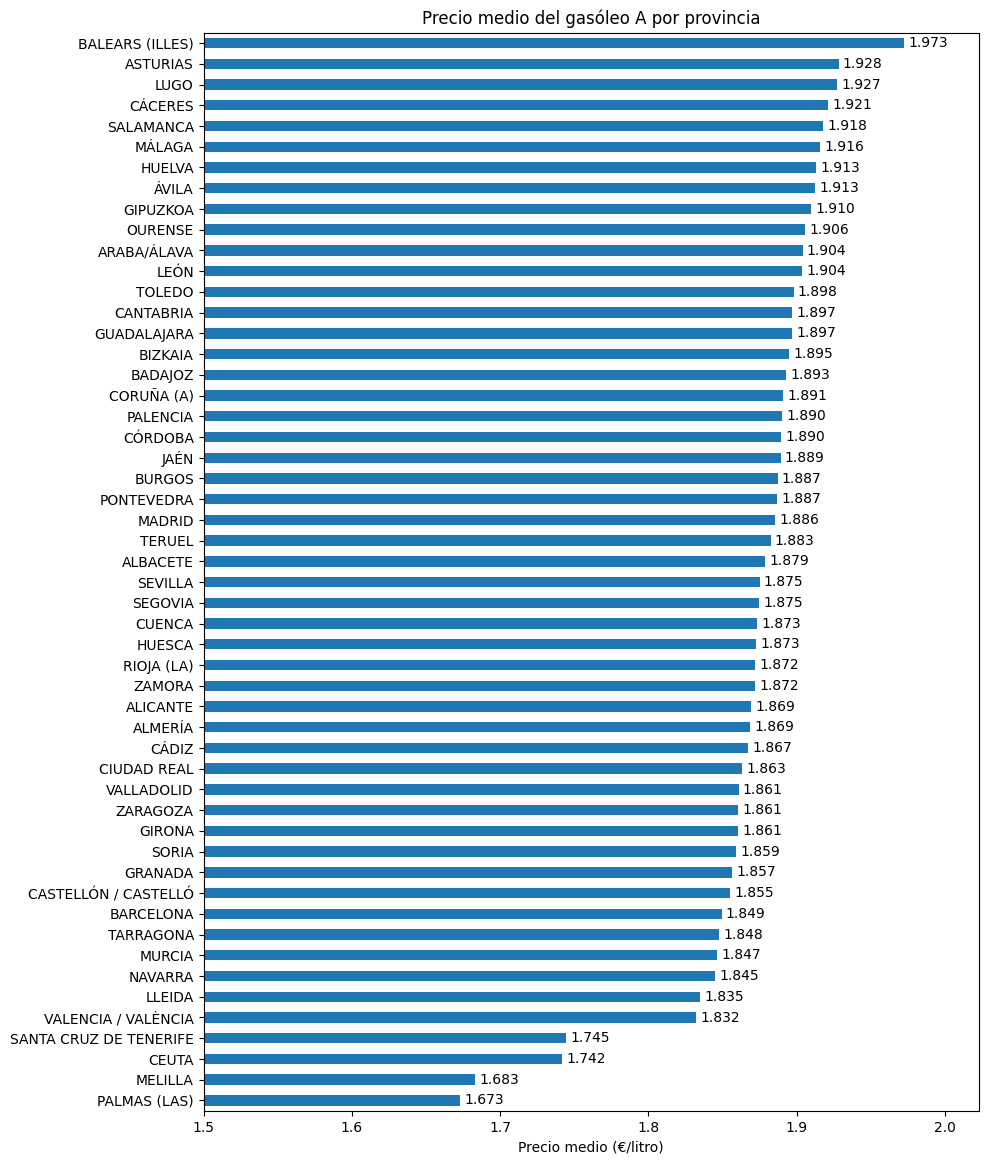

In [11]:
# [22]
# ["precio_gasoleo_a"].mean() calcula, dentro de cada grupo, la media del precio.
# sort_values() ordena el resultado de menor a mayor precio.
precio_por_provincia = gasolineras.groupby("Provincia")["precio_gasoleo_a"].mean().sort_values()

# Gráfico de barras horizontales (barh): una barra por provincia, con su precio medio.

ax = precio_por_provincia.plot(kind="barh", figsize=(10, 14))

plt.title("Precio medio del gasóleo A por provincia")
plt.xlabel("Precio medio (€/litro)")
plt.ylabel("")   # sin título en el eje vertical, los nombres de provincia ya se explican solos

# Empezamos el eje en 1.5 en vez de en 0. Si empezara en 0, todas las barras
# parecerían iguales, porque las diferencias entre provincias son de céntimos.
plt.xlim(1.5, precio_por_provincia.max() + 0.05)

# Escribimos el valor de cada barra al final de la barra, con 3 decimales
ax.bar_label(ax.containers[0], fmt="%.3f", padding=3)

plt.show()

**[23]**

**Observaciones del precio medio por provincia:**

* **Las cuatro provincias más baratas son Las Palmas (1,673 €/l), Melilla (1,683), Ceuta (1,742) y Santa Cruz de Tenerife (1,745)**,
  separadas del resto por un salto de casi 9 céntimos. Esto confirma la hipótesis del histograma:
  el grupo de gasolineras muy baratas corresponde a Canarias, Ceuta y Melilla, que tienen una fiscalidad diferente sobre los carburantes.
* **La provincia más cara es Baleares (1,973 €/l)**, 4,5 céntimos por encima de la segunda.
* En la **península**, las más caras son Asturias (1,928), Lugo (1,927), Cáceres (1,921), Salamanca (1,918) y Málaga (1,916),
  y las más baratas, Valencia (1,832) y Lleida (1,835). La diferencia dentro de la península es de unos 10 céntimos por litro.
* Estos resultados coinciden con los informes de la Comisión Nacional de los Mercados y la Competencia (CNMC),
  que también sitúan a Asturias, Salamanca y Málaga entre las provincias peninsulares con el gasóleo más caro.
* Conclusión para el modelo: **la provincia es una variable muy importante para predecir el precio**,
  sobre todo para distinguir Canarias, Ceuta y Melilla del resto.

In [12]:
# [24]
# nunique() cuenta cuántos valores DISTINTOS hay en la columna
print("Número de rótulos distintos:", gasolineras["Rótulo"].nunique())

# value_counts() cuenta cuántas gasolineras hay de cada rótulo, ordenado de más a menos.
# head(30) muestra solo los 30 primeros
gasolineras["Rótulo"].value_counts().head(30)

Número de rótulos distintos: 3568


,count
Rótulo,
REPSOL,2741
MOEVE,596
CEPSA,554
GALP,450
BALLENOIL,425
PLENERGY,398
SHELL,339
PETROPRIX,179
PETRONOR,158


Marcas principales: 22
marca
OTRAS        4721
REPSOL       2741
MOEVE         596
CEPSA         554
GALP          450
BALLENOIL     425
PLENERGY      398
SHELL         339
PETROPRIX     179
PETRONOR      158
CARREFOUR     146
BP            130
AVIA           99
Q8             80
ESCLATOIL      72
BONAREA        69
CAMPSA         56
VALCARCE       47
AGLA           46
ALCAMPO        45
HAM            42
ENI            42
EROSKI         40
Name: count, dtype: int64


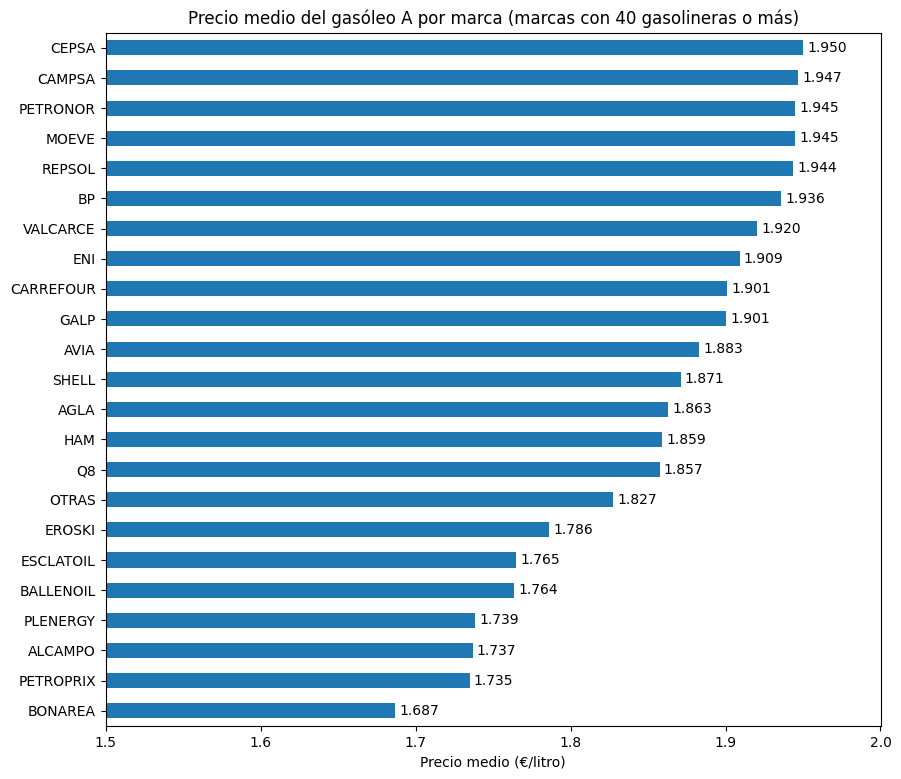

In [13]:
# [25]
# --- 1. Creamos la columna "marca" ---

# value_counts() cuenta las gasolineras de cada rótulo.
# Nos quedamos con los rótulos que tienen 40 gasolineras o más.
conteo_rotulos = gasolineras["Rótulo"].value_counts()
marcas_principales = conteo_rotulos[conteo_rotulos >= 40].index   # .index = los nombres de esos rótulos

print("Marcas principales:", len(marcas_principales))

# where(condición, otro_valor): deja el valor original donde la condición es True
# y pone "OTRAS" donde es False.
# isin(lista) comprueba si cada rótulo está en la lista de marcas principales.
gasolineras["marca"] = gasolineras["Rótulo"].where(gasolineras["Rótulo"].isin(marcas_principales), "OTRAS")

# Comprobación: cuántas gasolineras hay en cada marca
print(gasolineras["marca"].value_counts())


# --- 2. Gráfico: precio medio del gasóleo A por marca ---

# Igual que con las provincias: agrupamos por marca, calculamos la media del precio y ordenamos
precio_por_marca = gasolineras.groupby("marca")["precio_gasoleo_a"].mean().sort_values()

ax = precio_por_marca.plot(kind="barh", figsize=(10, 9))

plt.title("Precio medio del gasóleo A por marca (marcas con 40 gasolineras o más)")
plt.xlabel("Precio medio (€/litro)")
plt.ylabel("")

# Empezamos el eje en 1.5 para que se vean las diferencias de céntimos
plt.xlim(1.5, precio_por_marca.max() + 0.05)

# Valor de cada barra al final, con 3 decimales
ax.bar_label(ax.containers[0], fmt="%.3f", padding=3)

plt.show()

In [14]:
# [26]
# Provincias donde hay gasolineras BONAREA, y cuántas en cada una
gasolineras[gasolineras["marca"] == "BONAREA"]["Provincia"].value_counts()

,count
Provincia,
LLEIDA,21
BARCELONA,17
TARRAGONA,11
ZARAGOZA,8
CASTELLÓN / CASTELLÓ,4
HUESCA,4
GIRONA,2
NAVARRA,1
TERUEL,1


**[27]**

**Observaciones del precio medio por marca:**

* El 41 % de las gasolineras (4.721) son independientes o de marcas con menos de 40 gasolineras; las agrupo como "OTRAS".
  REPSOL sola tiene 2.741 gasolineras, casi una de cada cuatro.
* **Las grandes petroleras son las más caras**: CEPSA (1,950 €/l), CAMPSA (1,947), PETRONOR (1,945), MOEVE (1,945),
  REPSOL (1,944) y BP (1,936). MOEVE es el nuevo nombre de CEPSA, y CAMPSA y PETRONOR pertenecen al grupo Repsol.
* **Las gasolineras de bajo coste y de supermercados son las más baratas**: BONAREA (1,687), PETROPRIX (1,735),
  ALCAMPO (1,737), PLENERGY (1,739), BALLENOIL (1,764), ESCLATOIL (1,765) y EROSKI (1,786).
  Una excepción es CARREFOUR (1,901), que está más cerca de las grandes marcas.
* Las gasolineras del grupo "OTRAS" quedan en un punto intermedio (1,827).
* La diferencia entre la marca más cara y la más barata es de **26 céntimos por litro**, más del doble
  que la diferencia entre provincias de la península (unos 10 céntimos).
* Esto confirma la hipótesis del histograma: los dos picos corresponden a dos tipos de gasolineras,
  las grandes marcas (en torno a 1,95 €) y las de bajo coste (en torno a 1,75 €).
* Conclusión para el modelo: **la marca es probablemente la variable más importante** para predecir el precio.

*Nota:* la marca y la ubicación pueden estar mezcladas. Por ejemplo, las 69 gasolineras BONAREA están casi todas
en Cataluña (51) y Aragón (13), que ya son zonas con precios bajos; solo tiene 4 en Castellón y 1 en Navarra.
El modelo, al usar las dos variables a la vez, podrá separar el efecto de la marca del efecto de la ubicación.

**[28]**

### Horario y margen de la carretera

Por último, analizo si el precio cambia según el horario de apertura (abierta 24 horas o no)
y según el lado de la carretera en el que está la gasolinera (margen).

In [15]:
# [29]
# --- 1. Creamos una columna nueva que indique si la gasolinera abre 24 horas ---

# La columna "Horario" es texto, por ejemplo "L-D: 24H" o "L-D: 07:00-22:00".
# str.contains("24H") devuelve True si el texto contiene "24H" y False si no.
# na=False: si algún horario está vacío (nulo), lo consideramos False en vez de dar error.
# astype(int) convierte True/False en 1/0, que es como lo necesitará el modelo.
gasolineras["abierta_24h"] = gasolineras["Horario"].str.contains("24H", na=False).astype(int)

# Cuántas gasolineras abren 24 h (1) y cuántas no (0)
print(gasolineras["abierta_24h"].value_counts(), "\n")


# --- 2. Precio medio según el horario ---

# agg(["mean", "count"]) calcula a la vez la media del precio y el número de gasolineras de cada grupo
print("Precio medio según si abre 24 h (0 = no, 1 = sí):")
print(gasolineras.groupby("abierta_24h")["precio_gasoleo_a"].agg(["mean", "count"]).round(3), "\n")


# --- 3. Precio medio según el margen de la carretera ---

# D = derecho, I = izquierdo, N = no aplicable (no está en una carretera)
print("Precio medio según el margen:")
print(gasolineras.groupby("Margen")["precio_gasoleo_a"].agg(["mean", "count"]).round(3))

abierta_24h
0    6134
1    5341
Name: count, dtype: int64 

Precio medio según si abre 24 h (0 = no, 1 = sí):
              mean  count
abierta_24h              
0            1.905   6069
1            1.828   5188 

Precio medio según el margen:
         mean  count
Margen              
D       1.868   5940
I       1.902   2689
N       1.839   2628


In [16]:
# [30]
# Para cada marca, calculamos qué porcentaje de sus gasolineras abre 24 h.
# Como abierta_24h vale 0 o 1, su media es justo la proporción de gasolineras que abren 24 h
# (por ejemplo, una media de 0.8 = el 80 % abre 24 h). Multiplicamos por 100 para tener el porcentaje.
porcentaje_24h = (gasolineras.groupby("marca")["abierta_24h"].mean() * 100).round(1)

# Lo ordenamos de mayor a menor porcentaje y lo mostramos junto al precio medio de cada marca,
# para ver si las marcas baratas son las que más abren 24 h.
# pd.DataFrame({...}) crea una tabla con las dos columnas, emparejadas por marca.
tabla = pd.DataFrame({
    "% abiertas 24 h": porcentaje_24h,
    "precio medio": gasolineras.groupby("marca")["precio_gasoleo_a"].mean().round(3)
}).sort_values("% abiertas 24 h", ascending=False)

tabla

,% abiertas 24 h,precio medio
marca,,
PLENERGY,100.0,1.739
BALLENOIL,99.8,1.764
BONAREA,98.6,1.687
ESCLATOIL,98.6,1.765
PETROPRIX,97.2,1.735
HAM,92.9,1.859
CARREFOUR,77.4,1.901
ALCAMPO,73.3,1.737
Q8,70.0,1.857


**[31]**

**Observaciones del horario y el margen:**

* El 46 % de las gasolineras (5.341) abre 24 horas.
* **Las gasolineras abiertas 24 h son 7,7 céntimos más baratas** de media (1,828 €/l frente a 1,905 €/l).
  Parece contradictorio, porque abrir toda la noche debería ser más caro.
* La tabla anterior lo explica: **las marcas de bajo coste abren casi todas 24 h** (PLENERGY 100 %, BALLENOIL 99,8 %,
  BONAREA 98,6 %, ESCLATOIL 98,6 %, PETROPRIX 97,2 %), mientras que **las grandes marcas abren 24 h muy pocas veces**
  (REPSOL 22,4 %, CEPSA 18,6 %, PETRONOR 10,1 %, CAMPSA 8,9 %).
  Probablemente se debe a que muchas gasolineras de bajo coste son desatendidas (sin personal y con pago automático),
  así que abrir 24 h no les supone un coste extra.
* Por tanto, **el horario está relacionado con el precio, pero no es la causa**: las gasolineras baratas suelen abrir 24 h.
  Es un ejemplo de que correlación no implica causalidad.
* **Margen de la carretera:** las gasolineras que no están en carretera (N) son las más baratas (1,839 €/l),
  probablemente porque son urbanas o de supermercado y tienen más competencia cerca.
  Las del margen izquierdo (I, 1,902 €/l) son 3,4 céntimos más caras que las del derecho (D, 1,868 €/l).
  No he encontrado una explicación clara para esta diferencia.

**[32]**

### Correlaciones

La correlación mide la relación lineal entre dos variables numéricas, con un valor entre -1 y 1:
cerca de 1, suben a la vez; cerca de -1, cuando una sube la otra baja; cerca de 0, no hay relación lineal.

Solo se puede calcular con variables numéricas: la latitud, la longitud, el horario 24 h y el precio.
La provincia y la marca, que son texto, ya las he analizado antes con los precios medios por grupo.

precio_gasoleo_a    1.000
Latitud             0.288
Longitud            0.133
abierta_24h        -0.383
Name: precio_gasoleo_a, dtype: float64 



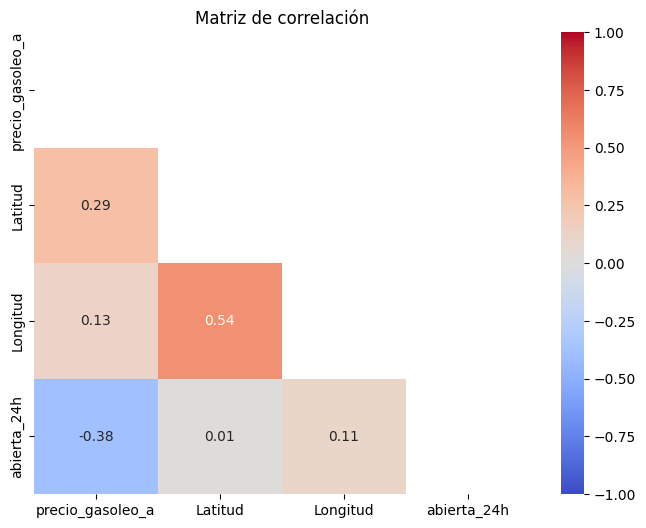

In [17]:
# [33]
# Columnas numéricas que vamos a comparar
columnas_correlacion = ["precio_gasoleo_a", "Latitud", "Longitud", "abierta_24h"]

# corr() calcula la correlación de cada columna con todas las demás -> una tabla (matriz) de 4x4
corr_matrix = gasolineras[columnas_correlacion].corr()

# Mostramos solo la correlación de cada variable con el precio, ordenada de mayor a menor

print(corr_matrix["precio_gasoleo_a"].sort_values(ascending=False).round(3), "\n")


# --- Mapa de calor de la matriz de correlación ---

# Máscara para ocultar la mitad superior de la matriz, porque es simétrica
# (la correlación de A con B es la misma que la de B con A, así que se vería repetida)
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

plt.figure(figsize=(8, 6))

# annot=True escribe el valor dentro de cada casilla; fmt=".2f" = con 2 decimales
# cmap="coolwarm": azul = correlación negativa, rojo = positiva
# vmin y vmax fijan la escala de -1 a 1, para que los colores sean comparables
sns.heatmap(corr_matrix, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)

plt.title("Matriz de correlación")
plt.show()

**[34]**

**Observaciones de las correlaciones:**

* La variable numérica más relacionada con el precio es **`abierta_24h` (-0,38)**: abrir 24 horas va asociado
  a un precio más bajo. Como vimos antes, se debe a que las marcas de bajo coste abren casi todas 24 h.
* **Latitud (0,29)**: cuanto más al norte está la gasolinera, algo más caro es el gasóleo. En parte se debe a Canarias,
  que está muy al sur y tiene precios mucho más bajos.
* **Longitud (0,13)**: relación muy débil con el precio.
* La correlación entre latitud y longitud (0,54) no tiene que ver con el precio: se debe a la forma del mapa,
  porque Canarias está a la vez muy al sur y muy al oeste del resto de España.
* Todas las correlaciones son débiles o moderadas. Las variables que más influyen en el precio, la marca y la provincia,
  no aparecen en esta matriz porque no son numéricas.

**[35]**

**Resumen de la exploración:**

1. Hay 218 gasolineras sin precio de gasóleo A (no lo venden) que habrá que eliminar.
2. He corregido una gasolinera con la latitud y la longitud intercambiadas y he eliminado 4 sin coordenadas.
3. El precio tiene dos picos: gasolineras de bajo coste (en torno a 1,75 €/l) y grandes marcas (en torno a 1,95 €/l).
4. **Ubicación**: Canarias, Ceuta y Melilla son mucho más baratas por su menor fiscalidad; Baleares es la más cara.
   Dentro de la península, la diferencia entre provincias es de unos 10 céntimos.
5. **Marca**: es la variable que más diferencia el precio, con 26 céntimos entre la más cara y la más barata.
6. **Horario**: las gasolineras 24 h son más baratas porque casi todas las de bajo coste abren 24 h.
7. **Margen**: las gasolineras que no están en carretera son las más baratas.

**[36]**

## 4. Exposición del objetivo

**Objetivo:** crear un modelo que **prediga el precio del gasóleo A** de una gasolinera a partir de sus características:
dónde está (latitud, longitud y provincia), de qué marca es, si abre 24 horas y en qué margen de la carretera se encuentra.

**Target (valor a predecir):** `precio_gasoleo_a`, en €/litro.

**Tipo de problema:**
* Es **aprendizaje supervisado**, porque tenemos el precio real de cada gasolinera (datos etiquetados).
* Es un problema de **regresión**, porque el valor a predecir es un número continuo, no una categoría.
* En concreto, es **regresión múltiple**, porque usamos varias características para hacer la predicción.

**Medidas de rendimiento:**
* **RMSE** (raíz del error cuadrático medio): el error típico de las predicciones, en €/litro.
  Por ejemplo, un RMSE de 0,05 significa que el modelo se equivoca, de media, en unos 5 céntimos.
* **R²** (coeficiente de determinación): qué proporción de la variación del precio explica el modelo,
  entre 0 (no explica nada) y 1 (lo explica todo).

**Utilidad:** un modelo así permitiría saber si una gasolinera tiene un precio alto o bajo para sus características,
o estimar a qué precio debería vender una gasolinera nueva según su marca y ubicación.

**[37]**

## 5. Preparación de los datos

Pasos para dejar los datos listos para entrenar el modelo:

1. Seleccionar solo las columnas que voy a usar.
2. Eliminar las gasolineras sin precio de gasóleo A.
3. Convertir las variables de texto (provincia, marca y margen) en números con la codificación *one-hot*.
4. Barajar los datos.
5. Separar las características (X) del valor a predecir (y).
6. Dividir los datos en entrenamiento (80 %) y prueba (20 %).

In [18]:
# [38]
# --- 1. Seleccionamos solo las columnas que vamos a usar ---

# copy() crea una tabla nueva e independiente. Así, si la modificamos,
# la tabla original "gasolineras" (la de la exploración) no cambia.
columnas_modelo = ["precio_gasoleo_a", "Latitud", "Longitud", "Provincia", "marca", "Margen", "abierta_24h"]
datos = gasolineras[columnas_modelo].copy()


# --- 2. Eliminamos las gasolineras que no tienen precio de gasóleo A ---

# Sin el valor a predecir no se puede entrenar ni comprobar el modelo, así que esas filas no sirven.
# dropna(subset=[...]) elimina las filas que tienen un nulo en las columnas indicadas.
filas_antes = len(datos)
datos = datos.dropna(subset=["precio_gasoleo_a"])
print("Filas eliminadas por no tener precio:", filas_antes - len(datos))


# --- 3. Comprobación: no debe quedar ningún nulo en ninguna columna ---

# isnull().sum() cuenta los nulos de cada columna; todos deberían ser 0
print("\nNulos por columna:")
print(datos.isnull().sum())

print("\nTamaño final:", datos.shape)

Filas eliminadas por no tener precio: 218

Nulos por columna:
precio_gasoleo_a    0
Latitud             0
Longitud            0
Provincia           0
marca               0
Margen              0
abierta_24h         0
dtype: int64

Tamaño final: (11257, 7)


**[39]**

Se han eliminado las 218 gasolineras sin precio. No tiene sentido rellenarlas (por ejemplo, con la mediana)
porque el nulo está en el valor a predecir: sería entrenar el modelo con precios inventados.

Quedan **11.257 gasolineras** y ninguna columna tiene valores nulos.

**Conversión de categorías a números:** la provincia, la marca y el margen son texto y no tienen un orden natural
(Madrid no es "mayor" que Sevilla). Uso la codificación *one-hot*: una columna de 0 o 1 para cada categoría.

**Escalado:** no escalo los datos. Los modelos basados en árboles (árbol de decisión y random forest) no se ven
afectados por la escala de las variables, y en la regresión lineal el escalado no cambia las predicciones.

In [19]:
# [40]
from sklearn.model_selection import train_test_split

# --- 1. Codificación one-hot de las variables de texto ---

# get_dummies crea una columna de 0/1 por cada valor distinto de las columnas indicadas.
# Por ejemplo, "Margen" (D, I, N) se convierte en Margen_D, Margen_I y Margen_N.
# Una gasolinera del margen derecho tendrá Margen_D = 1, Margen_I = 0 y Margen_N = 0.
# dtype=int hace que salgan 0 y 1 en vez de True y False
datos = pd.get_dummies(datos, columns=["Provincia", "marca", "Margen"], dtype=int)

print("Columnas después de one-hot:", datos.shape[1])   # 7 columnas se convierten en unas 80


# --- 2. Barajamos los datos ---

# El CSV viene ordenado por provincia (primero Albacete, luego Alicante...).
# sample(frac=1) coge el 100 % de las filas en orden aleatorio.
# random_state=42 hace que el "barajado" sea siempre el mismo, para que los resultados se puedan repetir.
datos = datos.sample(frac=1, random_state=42)


# --- 3. Separamos X (características) e y (valor a predecir) ---

y = datos["precio_gasoleo_a"]                  # lo que queremos predecir
X = datos.drop("precio_gasoleo_a", axis=1)     # todo lo demás; axis=1 = eliminar una columna (no una fila)


# --- 4. Dividimos en entrenamiento (80 %) y prueba (20 %) ---

# Con los datos de entrenamiento el modelo aprende.
# Los de prueba se guardan aparte y solo se usan al final, para ver cómo funciona con gasolineras que no ha visto nunca.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

print("Entrenamiento:", X_train.shape)   # unas 9.005 filas
print("Prueba:       ", X_test.shape)    # unas 2.252 filas

Columnas después de one-hot: 82
Entrenamiento: (9005, 81)
Prueba:        (2252, 81)


**[41]**

Tras la codificación one-hot, el dataset tiene 81 características: latitud, longitud, abierta_24h
y una columna de 0/1 por cada provincia, marca y margen.

* **Entrenamiento:** 9.005 gasolineras (80 %).
* **Prueba:** 2.252 gasolineras (20 %). Se guardan aparte y solo se usan al final para evaluar el modelo elegido.

**[42]**

## 6. Entrenamiento del modelo y comprobación del rendimiento

Voy a entrenar tres modelos de regresión y compararlos:

1. **Regresión lineal**
2. **Árbol de decisión**
3. **Random forest** (bosque aleatorio)

Para compararlos uso **validación cruzada** con 3 particiones sobre los datos de entrenamiento:
se divide el conjunto de entrenamiento en 3 partes, se entrena con 2 y se evalúa con la tercera,
y se repite 3 veces cambiando la parte de evaluación. El resultado es la media de las 3 evaluaciones.
Así se mide cómo funciona el modelo con datos que no ha visto, sin tocar todavía el conjunto de prueba.

In [20]:
# [43]
from sklearn.model_selection import cross_validate

# Lista donde iremos guardando los resultados de cada modelo, para compararlos al final en una tabla
resultados_cv = []

def evaluar_cv(modelo, nombre):
    # cross_validate entrena y evalúa el modelo 3 veces (cv=3), cada vez con una parte distinta para evaluar.
    # scoring indica qué medidas calcular:
    #   "neg_root_mean_squared_error" = RMSE, pero en negativo (scikit-learn lo da así porque
    #   en sus medidas "más alto es mejor"; luego le cambiamos el signo)
    #   "r2" = coeficiente de determinación R²
    puntuaciones = cross_validate(
        modelo, X_train, y_train, cv=3,
        scoring={"rmse": "neg_root_mean_squared_error", "r2": "r2"}
    )

    # Media de las 3 evaluaciones. El signo "-" vuelve el RMSE positivo.
    rmse = -puntuaciones["test_rmse"].mean()
    r2 = puntuaciones["test_r2"].mean()

    print(f"{nombre}: RMSE = {rmse:.4f} €/litro | R² = {r2:.4f}")

    # Devolvemos los resultados como un diccionario, para añadirlo a la lista resultados_cv
    return {"Modelo": nombre, "RMSE CV (€/litro)": rmse, "R² CV": r2}

In [21]:
# [44]
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# Creamos el modelo y lo entrenamos con los datos de entrenamiento.
# fit() es el entrenamiento: el modelo busca los coeficientes que mejor relacionan X con y.
modelo_lineal = LinearRegression()
modelo_lineal.fit(X_train, y_train)

# Predecimos sobre los mismos datos de entrenamiento, para ver un primer ejemplo de cómo acierta
y_pred_train = modelo_lineal.predict(X_train)

# Mostramos las 10 primeras gasolineras: precio real, estimado y error
print("Precio real   Precio estimado   Error absoluto")
for real, estimado in zip(y_train[:10], y_pred_train[:10]):   # zip recorre las dos listas a la vez
    print(f"{real:10.3f}   {estimado:14.3f}   {abs(real - estimado):14.3f}")

# Error sobre los datos de entrenamiento (sobre datos que el modelo YA ha visto)
rmse_train = np.sqrt(mean_squared_error(y_train, y_pred_train))
print(f"\nRMSE (entrenamiento): {rmse_train:.4f} €/litro")
print(f"R² (entrenamiento): {r2_score(y_train, y_pred_train):.4f}\n")

# Validación cruzada: error sobre datos que el modelo NO ha visto, que es el que importa
resultados_cv.append(evaluar_cv(modelo_lineal, "Regresión lineal"))

Precio real   Precio estimado   Error absoluto
     1.890            1.934            0.044
     1.699            1.648            0.051
     1.970            1.967            0.003
     1.959            1.977            0.018
     1.914            1.960            0.046
     1.969            1.963            0.006
     1.820            1.856            0.036
     1.969            1.943            0.026
     1.939            1.838            0.101
     1.699            1.814            0.115

RMSE (entrenamiento): 0.0634 €/litro
R² (entrenamiento): 0.6065

Regresión lineal: RMSE = 0.0641 €/litro | R² = 0.5979


**[45]**

**Resultados de la regresión lineal:**

* **RMSE en validación cruzada: 0,0641 €/litro.** El modelo se equivoca, de media, unos 6,4 céntimos por litro.
* **R² en validación cruzada: 0,598.** Explica aproximadamente el 60 % de la variación del precio entre gasolineras.
* Como referencia, la desviación típica del precio es de 0,10 €/litro: es el error típico que tendríamos
  si predijéramos siempre el precio medio, sin ningún modelo. La regresión lineal reduce el error de 10 a 6,4 céntimos.
* El error en entrenamiento (0,0634) es casi igual al de validación cruzada (0,0641), así que **no hay sobreajuste**:
  el modelo funciona igual de bien con gasolineras que no ha visto.

In [22]:
# [46]
from sklearn.tree import DecisionTreeRegressor

# Árbol de decisión: el modelo hace preguntas sucesivas sobre las características
# ("¿es REPSOL?", "¿latitud > 40?"...) hasta llegar a una predicción.
# random_state=42 para que el resultado sea siempre el mismo.
modelo_arbol = DecisionTreeRegressor(random_state=42)
modelo_arbol.fit(X_train, y_train)

# Error sobre los datos de entrenamiento
y_pred_train = modelo_arbol.predict(X_train)
rmse_train = np.sqrt(mean_squared_error(y_train, y_pred_train))
print(f"RMSE (entrenamiento): {rmse_train:.4f} €/litro")
print(f"R² (entrenamiento): {r2_score(y_train, y_pred_train):.4f}\n")

# Validación cruzada
resultados_cv.append(evaluar_cv(modelo_arbol, "Árbol de decisión"))

RMSE (entrenamiento): 0.0007 €/litro
R² (entrenamiento): 1.0000

Árbol de decisión: RMSE = 0.0794 €/litro | R² = 0.3818


**[47]**

**Resultados del árbol de decisión:**

* En entrenamiento, el error es prácticamente 0 (RMSE 0,0007, R² 1,000): el árbol ha memorizado el precio
  de cada gasolinera del conjunto de entrenamiento.
* En validación cruzada, el error sube a **0,0794 €/litro** (casi 8 céntimos) y el R² baja a **0,382**.
  Funciona peor que la regresión lineal con gasolineras que no ha visto.
* Esto es **sobreajuste** (*overfitting*): el modelo se ajusta tanto a los datos de entrenamiento que aprende
  también sus particularidades y su "ruido", en lugar de patrones generales, y no generaliza bien.
* Por eso no se debe elegir un modelo por cómo predice sobre sus propios datos de entrenamiento.

In [23]:
# [48]
from sklearn.ensemble import RandomForestRegressor

# Random forest: entrena muchos árboles de decisión distintos (100 por defecto),
# cada uno con una parte aleatoria de los datos y de las características,
# y la predicción final es la MEDIA de todos los árboles.
# Al promediar, los errores de memorizar de cada árbol se compensan entre sí y se reduce el sobreajuste.
# n_jobs=-1 usa todos los procesadores disponibles, para que tarde menos.
modelo_bosque = RandomForestRegressor(random_state=42, n_jobs=-1)
modelo_bosque.fit(X_train, y_train)

# Error sobre los datos de entrenamiento
y_pred_train = modelo_bosque.predict(X_train)
rmse_train = np.sqrt(mean_squared_error(y_train, y_pred_train))
print(f"RMSE (entrenamiento): {rmse_train:.4f} €/litro")
print(f"R² (entrenamiento): {r2_score(y_train, y_pred_train):.4f}\n")

# Validación cruzada
resultados_cv.append(evaluar_cv(modelo_bosque, "Random forest"))

RMSE (entrenamiento): 0.0221 €/litro
R² (entrenamiento): 0.9521

Random forest: RMSE = 0.0611 €/litro | R² = 0.6341


**[49]**

**Resultados del random forest:**

* **RMSE en validación cruzada: 0,0611 €/litro** (unos 6,1 céntimos) y **R² de 0,634**: es el mejor de los tres modelos.
* Sigue habiendo cierto sobreajuste (error de 0,022 en entrenamiento frente a 0,061 en validación cruzada),
  pero mucho menor que el del árbol de decisión. Al promediar 100 árboles distintos, los errores de cada árbol
  se compensan entre sí y el modelo generaliza mejor.

In [24]:
# [50]
# Convertimos la lista de resultados en una tabla y la ordenamos de menor a mayor error (menor RMSE = mejor modelo)
tabla_resultados = pd.DataFrame(resultados_cv).sort_values("RMSE CV (€/litro)").reset_index(drop=True)

# round(4) redondea a 4 decimales para que se lea mejor
tabla_resultados.round(4)

,Modelo,RMSE CV (€/litro),R² CV
0,Random forest,0.0611,0.6341
1,Regresión lineal,0.0641,0.5979
2,Árbol de decisión,0.0794,0.3818


**[51]**

**Comparativa de los tres modelos:**

El **random forest** es el modelo con menor error en validación cruzada (6,1 céntimos), seguido de la regresión lineal (6,4)
y, en último lugar, el árbol de decisión (7,9), que sufre sobreajuste.

A continuación intento mejorar el random forest ajustando sus hiperparámetros.

**[52]**

## Ajuste de hiperparámetros

Intento mejorar el random forest ajustando sus hiperparámetros, sin utilizar el conjunto de prueba.

Un **parámetro** es un valor que el modelo aprende de los datos. Un **hiperparámetro** se fija antes del entrenamiento
y controla cómo aprende el modelo. Ajusto estos tres:

* `n_estimators`: número de árboles del bosque.
* `max_depth`: profundidad máxima de cada árbol (cuántas preguntas seguidas puede hacer).
* `min_samples_leaf`: número mínimo de gasolineras en cada hoja final del árbol.

Uso **GridSearchCV**, que prueba todas las combinaciones de una rejilla de valores con validación cruzada
y se queda con la que da menor RMSE.

In [25]:
# [53]
from sklearn.model_selection import GridSearchCV

# Rejilla de valores a probar. GridSearchCV probará TODAS las combinaciones:
# 2 valores x 2 valores x 2 valores = 8 combinaciones
rejilla = {
    "n_estimators": [100, 200],       # 100 o 200 árboles
    "max_depth": [None, 20],          # None = sin límite de profundidad; 20 = como máximo 20 niveles
    "min_samples_leaf": [1, 3]        # mínimo 1 o 3 gasolineras por hoja
}

busqueda_grid = GridSearchCV(
    RandomForestRegressor(random_state=42, n_jobs=-1),   # el modelo base que vamos a ajustar
    param_grid=rejilla,                                  # los valores a probar
    cv=3,                                                # validación cruzada con 3 particiones
    scoring="neg_root_mean_squared_error"                # elegimos la combinación con menor RMSE
)

# Entrenamos: 8 combinaciones x 3 particiones = 24 entrenamientos.
busqueda_grid.fit(X_train, y_train)

# best_params_ = la mejor combinación encontrada
# best_score_ = su RMSE (en negativo, por eso le cambiamos el signo)
print("Mejores hiperparámetros:", busqueda_grid.best_params_)
print(f"RMSE CV del mejor modelo: {-busqueda_grid.best_score_:.4f} €/litro\n")

# best_estimator_ = el modelo con los mejores hiperparámetros, ya reentrenado con todos los datos de entrenamiento.
# Lo evaluamos con nuestra función, para tener también su R² y añadirlo a la tabla comparativa.
modelo_ajustado = busqueda_grid.best_estimator_
resultados_cv.append(evaluar_cv(modelo_ajustado, "Random forest ajustado"))

Mejores hiperparámetros: {'max_depth': 20, 'min_samples_leaf': 1, 'n_estimators': 200}
RMSE CV del mejor modelo: 0.0600 €/litro

Random forest ajustado: RMSE = 0.0600 €/litro | R² = 0.6466


**[54]**

**Resultados del ajuste de hiperparámetros:**

* Mejor combinación: **200 árboles** (`n_estimators=200`), **profundidad máxima de 20** (`max_depth=20`)
  y **mínimo 1 gasolinera por hoja** (`min_samples_leaf=1`).
* RMSE en validación cruzada: **0,0600 €/litro** (antes 0,0611) y R²: **0,647** (antes 0,634).
* La mejora es pequeña, pero se consigue sin tocar los datos de prueba. Es el mejor modelo de los cuatro probados.

**[55]**

## Evaluación final con los datos de prueba

Elijo el **random forest ajustado** por ser el de menor RMSE en validación cruzada.
Ahora lo evalúo, una única vez, con los datos de prueba: 2.252 gasolineras que el modelo no ha visto en ningún momento.

In [26]:
# [56]
# Predecimos el precio de las gasolineras de prueba con el modelo elegido
y_pred_test = modelo_ajustado.predict(X_test)

# Mostramos las 10 primeras: precio real, estimado y error
print("Precio real   Precio estimado   Error absoluto")
for real, estimado in zip(y_test[:10], y_pred_test[:10]):
    print(f"{real:10.3f}   {estimado:14.3f}   {abs(real - estimado):14.3f}")

# Medidas de rendimiento sobre el conjunto de prueba
rmse_test = np.sqrt(mean_squared_error(y_test, y_pred_test))
r2_test = r2_score(y_test, y_pred_test)

print(f"\nRMSE (prueba): {rmse_test:.4f} €/litro")
print(f"R² (prueba): {r2_test:.4f}")

Precio real   Precio estimado   Error absoluto
     1.960            1.959            0.001
     1.785            1.820            0.035
     1.940            1.845            0.095
     1.690            1.801            0.111
     1.989            1.909            0.080
     1.895            1.818            0.077
     1.890            1.916            0.026
     1.708            1.794            0.086
     1.719            1.857            0.138
     1.822            1.802            0.020

RMSE (prueba): 0.0565 €/litro
R² (prueba): 0.6810


**[57]**

**Resultados con los datos de prueba:**

* **RMSE: 0,0565 €/litro.** El modelo se equivoca, de media, unos 5,7 céntimos por litro con gasolineras que no había visto nunca.
* **R²: 0,681.** Explica el 68 % de la variación del precio entre gasolineras.
* El resultado es incluso algo mejor que el de la validación cruzada (0,0600). Esto confirma que el modelo
  **generaliza bien** y que la validación cruzada era una buena estimación de su rendimiento real.
* En un depósito de 50 litros, un error de 5,7 céntimos por litro equivale a unos 2,80 €.

**[58]**

## Importancia de las características

El random forest permite ver qué características ha usado más para hacer sus predicciones.

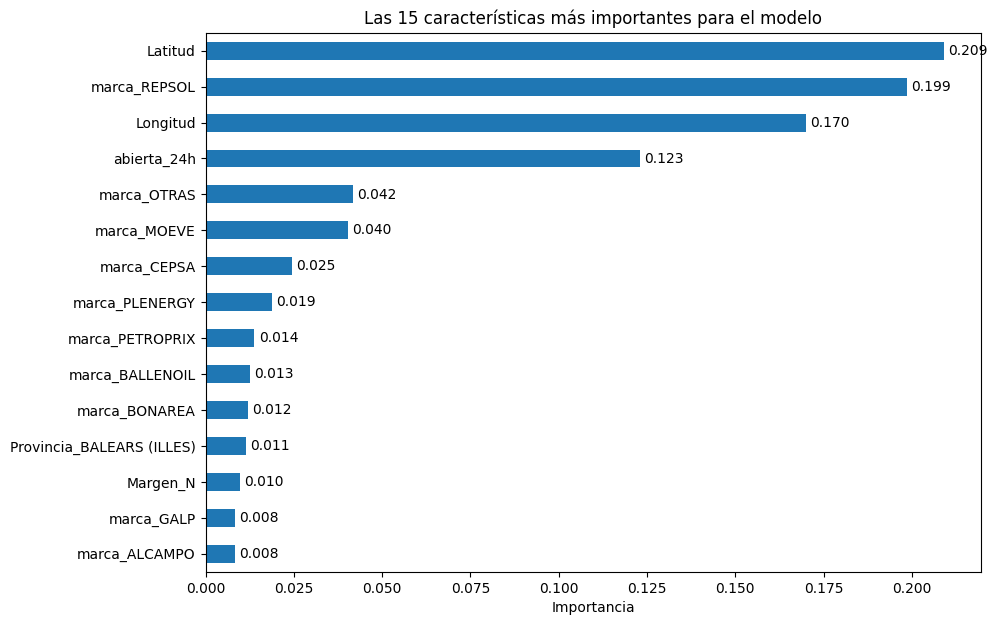

In [27]:
# [59]
# feature_importances_ indica cuánto ha usado el modelo cada característica para predecir.
# Los valores suman 1 entre todas: cuanto mayor, más importante.
# pd.Series(..., index=...) empareja cada importancia con el nombre de su columna.
importancias = pd.Series(modelo_ajustado.feature_importances_, index=X_train.columns)

# Nos quedamos con las 15 más importantes (de 81) y las ordenamos para el gráfico
top_15 = importancias.sort_values(ascending=False).head(15).sort_values()

# Gráfico de barras horizontales: la más importante sale arriba
ax = top_15.plot(kind="barh", figsize=(10, 7))
plt.title("Las 15 características más importantes para el modelo")
plt.xlabel("Importancia")
ax.bar_label(ax.containers[0], fmt="%.3f", padding=3)   # valor al final de cada barra
plt.show()

**[60]**

**Observaciones de la importancia de las características:**

* Las características más importantes son la **latitud (0,209)** y la **longitud (0,170)**: la ubicación es lo que más usa el modelo.
  Las columnas de provincia apenas aparecen porque las coordenadas ya aportan esa información de forma más precisa.
* **marca_REPSOL (0,199)** es la segunda más importante: al ser la marca con más gasolineras, saber si una gasolinera es o no de Repsol
  separa mucho entre precios altos y bajos.
* **abierta_24h (0,123)** es la cuarta. En parte refleja la marca, porque casi todas las gasolineras de bajo coste abren 24 horas.
* La marca aparece repartida en muchas columnas (una por marca, por la codificación one-hot), así que a continuación sumo
  las importancias por grupos para comparar de forma justa.
* Este tipo de importancia tiende a favorecer las variables numéricas continuas (como la latitud y la longitud)
  frente a las columnas de 0/1, así que la importancia de la ubicación puede estar algo sobrevalorada.

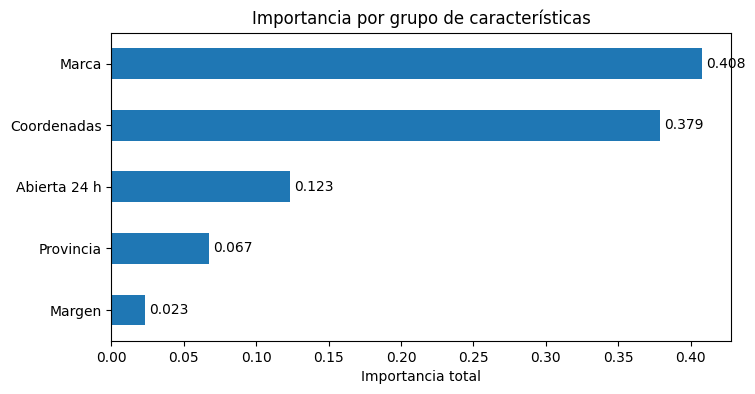

In [28]:
# [61]
# Función que, a partir del nombre de una columna, dice a qué grupo pertenece.
# Por ejemplo: "marca_REPSOL" -> "Marca", "Provincia_MADRID" -> "Provincia".
def grupo(columna):
    if columna.startswith("marca_"):
        return "Marca"
    elif columna.startswith("Provincia_"):
        return "Provincia"
    elif columna.startswith("Margen_"):
        return "Margen"
    elif columna in ["Latitud", "Longitud"]:
        return "Coordenadas"
    else:
        return "Abierta 24 h"   # la única que queda es abierta_24h

# groupby(función) aplica la función a cada nombre de columna y agrupa las importancias por el grupo que devuelve.
# sum() suma las importancias de cada grupo. El total de todos los grupos es 1.
importancia_grupos = importancias.groupby(grupo).sum().sort_values()

ax = importancia_grupos.plot(kind="barh", figsize=(8, 4))
plt.title("Importancia por grupo de características")
plt.xlabel("Importancia total")
ax.bar_label(ax.containers[0], fmt="%.3f", padding=3)
plt.show()

**[62]**

**Observaciones de la importancia por grupos:**

* Sumando las importancias de todas sus columnas, la **marca (0,408)** es el grupo más importante,
  seguida muy de cerca por las **coordenadas (0,379)**.
* Si se considera la ubicación en conjunto (coordenadas + provincia = 0,446), **marca y ubicación pesan prácticamente lo mismo**:
  entre las dos explican la mayor parte de las predicciones del modelo.
* El **horario 24 h (0,123)** tiene una importancia menor, y en parte refleja la marca.
* El **margen de la carretera (0,023)** apenas influye.

**[63]**

## 7. Conclusiones

**Sobre los datos:**

* Los datos públicos del Ministerio permiten analizar los precios de 11.479 gasolineras de toda España.
  Hubo que resolver varios problemas: el servidor bloquea las conexiones desde Google Colab, los números venían con coma decimal,
  una gasolinera tenía las coordenadas intercambiadas y cuatro no tenían coordenadas.
* La exploración mostró que **el precio del gasóleo A depende sobre todo de dos factores**:
  * **La marca:** las grandes petroleras (CEPSA, REPSOL, BP...) son hasta 26 céntimos por litro más caras
    que las de bajo coste y supermercados (BONAREA, PETROPRIX, PLENERGY...).
  * **La ubicación:** Canarias, Ceuta y Melilla son mucho más baratas por su menor fiscalidad, y Baleares es la provincia más cara.
    Dentro de la península, la diferencia entre provincias es de unos 10 céntimos.
* Estos resultados coinciden con los informes de la CNMC, que sitúan a las grandes marcas y a provincias como Asturias,
  Salamanca y Málaga entre las más caras.
* Las gasolineras abiertas 24 horas son más baratas, pero no por el horario: casi todas las de bajo coste abren 24 h.
  **Que dos variables estén relacionadas no significa que una cause la otra.**

**Sobre los modelos:**

| Modelo | RMSE validación cruzada (€/l) | R² validación cruzada |
|---|---|---|
| Random forest ajustado | 0,0600 | 0,647 |
| Random forest | 0,0611 | 0,634 |
| Regresión lineal | 0,0641 | 0,598 |
| Árbol de decisión | 0,0794 | 0,382 |

* El **árbol de decisión** sufrió un fuerte **sobreajuste**: memorizó los datos de entrenamiento (error casi 0)
  pero fue el peor con datos nuevos. Por eso nunca se debe elegir un modelo por su rendimiento sobre los datos de entrenamiento.
* El **random forest ajustado** (200 árboles, profundidad máxima 20) fue el mejor. Con los datos de prueba, que no había visto nunca,
  se equivoca de media **5,7 céntimos por litro** y explica el **68 % de la variación del precio**.
* El modelo confirma lo visto en la exploración: **la marca y la ubicación son, con diferencia, las características más importantes.**

**Limitaciones y posibles mejoras:**

* Los datos son una "foto" de un momento concreto (9 de noviembre de 2026, 9:42 h). Los precios cambian a diario,
  así que el modelo habría que reentrenarlo con datos actuales.
* El modelo no explica el 32 % restante de la variación. Influyen factores que no están en el dataset,
  como la competencia cercana, el volumen de ventas o si la gasolinera está en una autopista.
* Posibles mejoras: calcular el número de gasolineras cercanas a cada una (competencia), usar datos de varios días,
  o probar otros algoritmos.